# CDC PTB · подготовка когорты

## tl;dr

Этот ноутбук собирает одноплодные живорождения резиденток США с известным акушерским сроком при родах. В проверенном прогоне: **3 480 382 записи за 2023** и **3 512 780 за 2024** год. Строка CDC — ребёнок при рождении, а не наблюдаемая по неделям беременность.

## Контекст и методы

Источник: `data/processed/cdc_natality/natality_ml_2023_2024.sqlite`, подготовленный из NCHS/NBER. Контракт: [MODEL_INPUT_CONTRACT.md](MODEL_INPUT_CONTRACT.md). Классы исхода: `<32`, `32–33`, `34–36`, `≥37` завершённых недель. Только одно разбиение 2023 года: train 60%, validation 20%, calibration 20%; 2024 сохраняется целиком для временной проверки. ID матери нет, поэтому разные беременности одной женщины могут попасть в разные части.

In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 115, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .16})
BLUE, ORANGE, GOLD, SLATE = "#28628A", "#BA6234", "#B78918", "#3B4855"
from src.data.preterm_cdc import OUT, BASE_FEATURES, CLASS_NAMES, prepare_all, load_year

## Данные · построение и сверка численности

In [4]:
manifest = prepare_all()
counts = pd.DataFrame({year: info["counts"] for year, info in manifest["years"].items()}).T.fillna(0).astype(int)
display(counts)
assert counts.loc["2023", "rows"] > 3_000_000 and counts.loc["2024", "rows"] > 3_000_000

,rows,band_3,band_2,band_0,band_1,partition_train,partition_calibration,partition_validation,partition_temporal_test
2023,3480382,3177381,227587,43650,31764,2088502,696392,695488,0
2024,3512780,3205168,232027,43577,32008,0,0,0,3512780


## Результаты · исходы и пропуски

,<32,32–33,34–36,≥37
Год,,,,
2023,1.25,0.91,6.54,91.29
2024,1.24,0.91,6.61,91.24


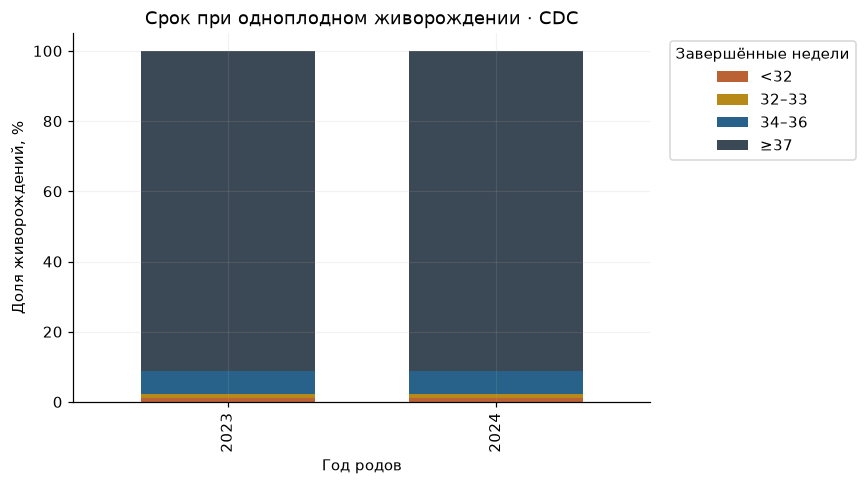

In [6]:
year_counts = counts[[f"band_{i}" for i in range(4)]].rename(columns={f"band_{i}": CLASS_NAMES[i] for i in range(4)})
share = year_counts.div(year_counts.sum(axis=1), axis=0) * 100
display(share.round(2).rename_axis("Год"))
fig, ax = plt.subplots(figsize=(8, 4.5))
share.plot.bar(stacked=True, ax=ax, color=[ORANGE, GOLD, BLUE, SLATE], width=.65)
ax.set(xlabel="Год родов", ylabel="Доля живорождений, %", title="Срок при одноплодном живорождении · CDC")
ax.legend(title="Завершённые недели", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

,"2023, %","2024, %"
maternal_age_at_birth,0.00,0.00
prepregnancy_bmi,2.24,2.34
previous_live_births,0.24,0.35
previous_terminations,0.28,0.38
previous_preterm_birth,0.14,0.13
chronic_hypertension,0.14,0.13
preexisting_diabetes,0.14,0.13
previous_cesarean,0.14,0.13
prepregnancy_cigarettes_per_day,0.39,0.45


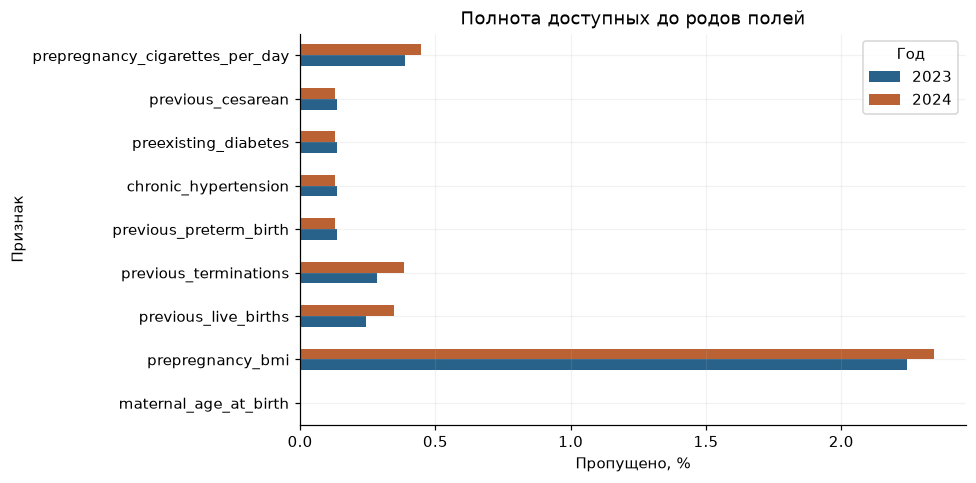

In [7]:
missing = pd.DataFrame({year: info["missing_features"] for year, info in manifest["years"].items()}).T
missing_pct = missing.div(counts["rows"], axis=0) * 100
display(missing_pct.round(2).T.rename(columns={"2023": "2023, %", "2024": "2024, %"}))
fig, ax = plt.subplots(figsize=(9, 4.5))
missing_pct.T.plot.barh(ax=ax, color=[BLUE, ORANGE])
ax.set(xlabel="Пропущено, %", ylabel="Признак", title="Полнота доступных до родов полей")
ax.legend(title="Год"); plt.tight_layout(); plt.show()

## Выводы

Результаты относятся только к одноплодным **живорождениям**. Возраст матери записан при родах и служит приближением более раннего возраста. Многоплодие, мертворождения, самопроизвольность родов и события беременности по неделям этой таблицей не определяются. Следующий ноутбук подбирает параметры только по 2023 году.